# Experiment C — does building a graph leak the study into a disease classifier?

Phase 5e measured batch leakage for flat models: random k-fold beats
leave-one-project-out (LOPO) for every disease, by up to +0.25 AUC, because test samples
share studies with training samples and the model partly recognises the study. A graph
can add new paths to the study. This notebook trains **the same GraphSAGE disease
classifier on four graphs** and measures what each one does to the score:

| graph | what it adds | the question |
|---|---|---|
| **G1** | samples, taxa, taxonomy | the honest baseline: no sample–sample path |
| **G2** | + each sample linked to its 10 most similar samples | does a similarity graph leak? |
| **G2 filtered** | G2 with every same-study link deleted | does deleting them fix it? |
| **G3** | + one node per study, linked to its samples | the study itself in the graph: the worst case |

Whether a graph *can* leak depends on how it is used, so every graph is run under three
**protocols**, from strict to leaky:

| protocol | held-out samples… | can a held-out sample reach a label? |
|---|---|---|
| **inductive** | only receive messages (`gnn.receivers_only`) | no |
| **transductive** | stay in the graph and send messages; only their labels are hidden | no — features travel, labels don't |
| **transductive + labels as input** | as transductive, and every training sample's label is an input feature (the "label as feature" practice behind label-propagation-style GNNs) | yes — through its neighbours |

and under **both** split schemes, because they answer different questions. Under LOPO the
whole test study is held out, so its same-study neighbours and its study node have no
labelled samples behind them. Under random k-fold, test samples sit next to labelled
samples from their own study — the setting where a graph can amplify the shortcut flat
models already exploit.

Taxon statistics and sample-feature scaling are fit on training rows per fold in every
protocol, so the protocols differ only in what flows through the graph. The folds are
exactly those of the committed `reports/classifier_cv.csv`. The gaps can be small, so every
configuration is trained with three seeds and read against seed-to-seed noise.

Runs are saved to `reports/graph_leakage_cv.csv` after each one, and a re-run skips every
(disease, protocol, graph, seed) already there — delete the file to recompute from scratch.

Outputs: `reports/graph_leakage_cv.csv` (one row per fold), `reports/graph_leakage_gap.csv`
(the summary), `reports/figures/phase7_leakage_gap.png`.

## Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import differential as diff
from src import gnn
from src import graphs as gr
from src import variance as var

REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
INTERIM = ROOT / "data" / "interim"
PROCESSED = ROOT / "data" / "processed"
REL_PATH = PROCESSED / "abund_relative.parquet"
CLR_PATH = PROCESSED / "abund_clr.parquet"

with open(ROOT / "config" / "params.yaml") as f:
    params = yaml.safe_load(f)
SEED = params["seed"]
dcfg = params["differential"]
gcfg = params["graph"]
tcfg = gcfg["train"]
lcfg = gcfg["leakage"]

import torch
import torch_geometric
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

print(f"seed={SEED}  torch={torch.__version__}  torch_geometric={torch_geometric.__version__}")
print(f"protocols={lcfg['protocols']}  variants={lcfg['variants']}  model seeds={lcfg['seeds']}  "
      f"k-NN k={gcfg['knn_k']}  epochs={tcfg['epochs']}")

C:\Users\Jadrovski\vnp\MicroWave\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


seed=42  torch=2.14.0+cpu  torch_geometric=2.8.1
protocols=['inductive', 'transductive', 'transductive_labels']  variants=['G1', 'G2', 'G2_filtered', 'G3']  model seeds=[42, 43, 44]  k-NN k=10  epochs=60


## 1 — The disease populations

The same per-category populations and folds as the committed flat baselines: the
within-project cohort expanded into one contrast per disease category, IBD subtypes
pooled. The folds come from `SEED` only; the three model seeds change initialisation and
training order, never which samples are tested.

In [2]:
cohort = pd.read_parquet(PROCESSED / "cohort_within_project.parquet")
frame = diff.build_analysis_frame(cohort, dcfg["category_groups"])
flat = pd.read_csv(REPORTS / "classifier_cv.csv")
categories = sorted(flat["disease_category"].unique())

taxa = [c for c in pq.ParquetFile(CLR_PATH).schema.names if c != gr.SAMPLE_COL]
taxonomy = gr.build_taxonomy_edges(pd.read_parquet(INTERIM / "taxon_table.parquet"), taxa)
sample_depth = pd.read_parquet(INTERIM / "sample_depth.parquet")
harmonized = pd.read_parquet(INTERIM / "samples_harmonized.parquet")

def category_data(cat):
    sub = frame[frame["disease_category"] == cat].drop_duplicates("sample").reset_index(drop=True)
    samples = sub["sample"].tolist()
    projects = sub["project"].to_numpy()
    y = sub["y"].to_numpy(int)
    bipartite = gr.build_bipartite_edges(REL_PATH, CLR_PATH, samples, taxa)
    ids, clr, _ = var.load_abundance_subset(CLR_PATH, set(samples))
    _, clr = var.align(ids, clr, samples)
    sx, names = gr.sample_node_features(sample_depth, samples)
    return dict(
        samples=samples, projects=projects, y=y, bipartite=bipartite, clr=clr,
        presence=gr.presence_from_edges(bipartite[0], len(samples), len(taxa)),
        sample_x=sx, sample_feature_names=names,
        knn=gr.build_knn_edges(clr, samples, projects, gcfg["knn_k"]),
        knn_filtered=gr.build_knn_edges(clr, samples, projects, gcfg["knn_k"],
                                        drop_same_project=True),
        project_x=gr.project_node_features(harmonized, sorted(set(projects)))[0],
        schemes=gnn.disease_folds(y, projects, SEED,
                                  n_splits=dcfg["batch_leakage"]["cv_folds"]))

data = {cat: category_data(cat) for cat in categories}
pd.DataFrame({cat: dict(samples=len(d["samples"]), cases=int(d["y"].sum()),
                        projects=len(set(d["projects"])),
                        lopo_folds=len(d["schemes"]["leave_project_out"]),
                        random_folds=len(d["schemes"].get("random_kfold", [])))
              for cat, d in data.items()}).T

,samples,cases,projects,lopo_folds,random_folds
HIV,507,359,3,3,5
IBD,708,557,4,4,5
NAFLD,215,104,3,3,5
T1D,223,100,2,2,5
asthma,468,248,3,3,5
cancer_other,960,657,4,4,5


## 2 — The mechanism: how many of a sample's nearest neighbours share its study?

If similar samples are mostly from the same study, a similarity graph is mostly a
study graph. This is measured on the directed 10-NN choices, before anything is deleted.

In [3]:
mechanism = pd.DataFrame({
    cat: dict(pct_same_project_neighbours=d["knn"][4],
              knn_edges=d["knn"][0].shape[1],
              knn_edges_after_filter=d["knn_filtered"][0].shape[1])
    for cat, d in data.items()}).T
mechanism["pct_same_project_neighbours"] = mechanism["pct_same_project_neighbours"].astype(float)
mechanism.round(3)

,pct_same_project_neighbours,knn_edges,knn_edges_after_filter
HIV,0.830,8454.0,1688.0
IBD,0.759,12024.0,3112.0
NAFLD,0.900,3336.0,416.0
T1D,0.925,3428.0,294.0
asthma,0.873,7438.0,962.0
cancer_other,0.847,15886.0,2520.0


## 3 — The same GraphSAGE on four graphs × three protocols × two split schemes × three seeds

`make_graph` builds a fold's graph with training-row statistics; `gnn.graph_disease_cv`
applies the protocol. One line is printed per (disease, protocol, graph, seed) as it
finishes, and the results file is rewritten after each, so an interrupted run resumes
where it stopped.

In [4]:
sage_cfg = {k: v for k, v in gcfg["models"]["graphsage"].items() if k != "aggr"}
make_sage = lambda g: gnn.HeteroSAGE(g, 1, embed_dim=gcfg["taxon_embed_dim"], **sage_cfg)

def make_graph(d, variant):
    extra = {"G2": dict(knn=d["knn"]), "G2_filtered": dict(knn=d["knn_filtered"]),
             "G3": dict(project_x=d["project_x"])}.get(variant, {})
    def build(train_idx):
        g = gr.build_hetero_graph(
            variant.split("_")[0], d["samples"], projects=d["projects"], taxonomy=taxonomy,
            bipartite=d["bipartite"], sample_x=d["sample_x"],
            sample_feature_names=d["sample_feature_names"], taxa_cols=taxa,
            leaf_stats=gr.taxon_leaf_stats(d["clr"], d["presence"], train_idx), y=d["y"],
            **extra)
        return gnn.scale_sample_features(g, train_idx)
    return build

CV_PATH = REPORTS / "graph_leakage_cv.csv"
cols = ["disease_category", "protocol", "graph", "seed", "cv_scheme", "fold", "auc",
        "balanced_accuracy", "n_train", "n_test", "n_test_pos", "test_project", "seconds"]
if CV_PATH.exists():
    # rows written before protocols existed are the inductive arm
    cv_all = pd.read_csv(CV_PATH, keep_default_na=False, na_values=[""])
    if "protocol" not in cv_all.columns:
        cv_all["protocol"] = "inductive"
    cv_all["test_project"] = cv_all["test_project"].fillna("")
    cv_all = cv_all[cols]
else:
    cv_all = pd.DataFrame(columns=cols)
done = set(map(tuple, cv_all[["disease_category", "protocol", "graph", "seed"]]
                     .drop_duplicates().itertuples(index=False)))
print(f"{len(done)} of {len(categories) * len(lcfg['protocols']) * len(lcfg['variants']) * len(lcfg['seeds'])} "
      f"runs already in {CV_PATH.name}")

t_all = time.time()
for protocol in lcfg["protocols"]:
    for cat in categories:
        d = data[cat]
        for variant in lcfg["variants"]:
            for seed in lcfg["seeds"]:
                if (cat, protocol, variant, seed) in done:
                    continue
                t0 = time.time()
                cv = gnn.graph_disease_cv(
                    make_graph(d, variant), make_sage, d["schemes"], d["y"], d["projects"], seed,
                    epochs=tcfg["epochs"], batch_size=tcfg["batch_size"], lr=tcfg["lr"],
                    weight_decay=tcfg["weight_decay"], neighbor_sampling=gcfg["neighbor_sampling"],
                    protocol=protocol)
                cv = cv.assign(disease_category=cat, protocol=protocol, graph=variant, seed=seed)
                cv_all = pd.concat([cv_all, cv[cols]], ignore_index=True)
                cv_all.to_csv(CV_PATH, index=False)
                means = cv.groupby("cv_scheme")["auc"].mean()
                print(f"{protocol:19s} {cat:13s} {variant:12s} seed {seed}: "
                      f"LOPO AUC {means.get('leave_project_out', np.nan):.3f}  "
                      f"random AUC {means.get('random_kfold', np.nan):.3f}  "
                      f"[{(time.time() - t0) / 60:.1f} min]", flush=True)

for c in ("seed", "fold", "n_train", "n_test", "n_test_pos"):
    cv_all[c] = cv_all[c].astype(int)
for c in ("auc", "balanced_accuracy", "seconds"):
    cv_all[c] = cv_all[c].astype(float)
print(f"all runs done in {(time.time() - t_all) / 60:.0f} min; {len(cv_all):,} fold rows")

216 of 216 runs already in graph_leakage_cv.csv
all runs done in 0 min; 1,764 fold rows


## 4 — The gaps, each read against seed noise

Per (disease, protocol, scheme, graph, seed) the AUC is averaged over folds; the table
reports the mean over seeds and the seed-to-seed sd. Each graph gap is computed within a
seed (same folds, same test samples, same seed, same protocol — only the graph differs) and
then averaged, so its sd is the noise a gap has to clear. `fold_sd` is the spread across
folds, shown because with 2–4 LOPO folds it is wide.

In [5]:
keys = ["disease_category", "protocol", "cv_scheme"]
per_seed = (cv_all.groupby(keys + ["graph", "seed"])["auc"]
            .agg(auc="mean", fold_sd="std").reset_index())
auc_summary = (per_seed.groupby(keys + ["graph"])
               .agg(auc_mean=("auc", "mean"), auc_seed_sd=("auc", "std"),
                    fold_sd=("fold_sd", "mean")).reset_index())

wide = per_seed.pivot_table(index=keys + ["seed"], columns="graph", values="auc")
gaps = pd.DataFrame({
    "graph_leakage_gap": wide["G2"] - wide["G1"],
    "gap_G2_filtered": wide["G2_filtered"] - wide["G1"],
    "gap_G3": wide["G3"] - wide["G1"],
}).groupby(keys).agg(["mean", "std"])
gaps.columns = [f"{g}_seed_sd" if s == "std" else g for g, s in gaps.columns]

aucs = auc_summary.pivot_table(index=keys, columns="graph", values="auc_mean")
aucs.columns = [f"auc_{g}" for g in aucs.columns]
flat_auc = (flat.groupby(["disease_category", "cv_scheme", "model"])["auc"].mean()
            .unstack("model").add_prefix("flat_auc_"))
gap_table = (aucs.join(gaps)
             .join(flat_auc, on=["disease_category", "cv_scheme"])
             .join(mechanism[["pct_same_project_neighbours"]], on="disease_category")
             .reset_index())
order = {p: i for i, p in enumerate(gnn.PROTOCOLS)}
gap_table = gap_table.sort_values(["protocol", "disease_category", "cv_scheme"],
                                  key=lambda s: s.map(order) if s.name == "protocol" else s)
gap_table.to_csv(REPORTS / "graph_leakage_gap.csv", index=False)
gap_table.round(3)

,disease_category,protocol,cv_scheme,auc_G1,auc_G2,auc_G2_filtered,auc_G3,graph_leakage_gap,graph_leakage_gap_seed_sd,gap_G2_filtered,gap_G2_filtered_seed_sd,gap_G3,gap_G3_seed_sd,flat_auc_gboost,flat_auc_logreg,pct_same_project_neighbours
0,HIV,inductive,leave_project_out,0.516,0.517,0.520,0.504,0.001,0.023,0.004,0.006,-0.012,0.025,0.532,0.542,0.830
1,HIV,inductive,random_kfold,0.760,0.760,0.760,0.765,-0.000,0.015,0.000,0.014,0.005,0.008,0.785,0.680,0.830
6,IBD,inductive,leave_project_out,0.694,0.683,0.688,0.695,-0.010,0.003,-0.005,0.008,0.001,0.014,0.730,0.701,0.759
7,IBD,inductive,random_kfold,0.795,0.794,0.795,0.806,-0.001,0.004,-0.001,0.005,0.011,0.008,0.819,0.747,0.759
12,NAFLD,inductive,leave_project_out,0.707,0.703,0.699,0.695,-0.004,0.014,-0.008,0.008,-0.012,0.005,0.673,0.626,0.900
13,NAFLD,inductive,random_kfold,0.768,0.771,0.769,0.763,0.003,0.004,0.001,0.008,-0.005,0.012,0.757,0.761,0.900
18,T1D,inductive,leave_project_out,0.402,0.396,0.406,0.400,-0.006,0.008,0.004,0.005,-0.002,0.001,0.480,0.401,0.925
19,T1D,inductive,random_kfold,0.559,0.554,0.554,0.535,-0.005,0.007,-0.005,0.020,-0.024,0.029,0.579,0.614,0.925
24,asthma,inductive,leave_project_out,0.536,0.528,0.517,0.536,-0.009,0.013,-0.020,0.017,0.000,0.006,0.546,0.588,0.873
25,asthma,inductive,random_kfold,0.527,0.522,0.510,0.510,-0.005,0.007,-0.018,0.008,-0.017,0.021,0.605,0.598,0.873


In [6]:
def reading(mean, sd):
    if np.isnan(mean):
        return ""
    if abs(mean) <= 2 * sd:
        return "within seed noise"
    return "graph raises AUC" if mean > 0 else "graph lowers AUC"

rows = []
for r in gap_table.itertuples(index=False):
    for name in ("graph_leakage_gap", "gap_G2_filtered", "gap_G3"):
        m, s = getattr(r, name), getattr(r, f"{name}_seed_sd")
        rows.append(dict(protocol=r.protocol, disease_category=r.disease_category,
                         cv_scheme=r.cv_scheme, comparison=name, gap=round(m, 3),
                         seed_sd=round(s, 3), reading=reading(m, s)))
readings = pd.DataFrame(rows)
print("gaps outside 2x seed sd, per protocol and scheme (of 18 each):")
print(readings.assign(flag=readings["reading"] != "within seed noise")
      .groupby(["protocol", "cv_scheme"], sort=False)["flag"].sum().to_string())
readings.pivot_table(index=["protocol", "disease_category", "comparison"], columns="cv_scheme",
                     values="gap", aggfunc="first").round(3)

gaps outside 2x seed sd, per protocol and scheme (of 18 each):
protocol             cv_scheme        
inductive            leave_project_out    4
                     random_kfold         1
transductive         leave_project_out    2
                     random_kfold         5
transductive_labels  leave_project_out    1
                     random_kfold         5


cv_scheme                                               leave_project_out  \
protocol            disease_category comparison                             
inductive           HIV              gap_G2_filtered                0.004   
                                     gap_G3                        -0.012   
                                     graph_leakage_gap              0.001   
                    IBD              gap_G2_filtered               -0.005   
                                     gap_G3                         0.001   
                                     graph_leakage_gap             -0.010   
                    NAFLD            gap_G2_filtered               -0.008   
                                     gap_G3                        -0.012   
                                     graph_leakage_gap             -0.004   
                    T1D              gap_G2_filtered                0.004   
                                     gap_G3                        -0.002   
                                     graph_leakage_gap             -0.006   
                    asthma           gap_G2_filtered               -0.020   
                                     gap_G3                         0.000   
                                     graph_leakage_gap             -0.009   
                    cancer_other     gap_G2_filtered                0.005   
                                     gap_G3                        -0.006   
                                     graph_leakage_gap              0.000   
transductive        HIV              gap_G2_filtered                0.000   
                                     gap_G3                        -0.005   
                                     graph_leakage_gap             -0.000   
                    IBD              gap_G2_filtered               -0.014   
                                     gap_G3                        -0.003   
                                     graph_leakage_gap             -0.010   
                    NAFLD            gap_G2_filtered               -0.011   
                                     gap_G3                        -0.012   
                                     graph_leakage_gap             -0.012   
                    T1D              gap_G2_filtered                0.001   
                                     gap_G3                        -0.008   
                                     graph_leakage_gap              0.006   
                    asthma           gap_G2_filtered               -0.010   
                                     gap_G3                         0.017   
                                     graph_leakage_gap             -0.005   
                    cancer_other     gap_G2_filtered                0.007   
                                     gap_G3                        -0.001   
                                     graph_leakage_gap              0.001   
transductive_labels HIV              gap_G2_filtered               -0.012   
                                     gap_G3                        -0.007   
                                     graph_leakage_gap              0.001   
                    IBD              gap_G2_filtered                0.005   
                                     gap_G3                         0.008   
                                     graph_leakage_gap              0.003   
                    NAFLD            gap_G2_filtered                0.008   
                                     gap_G3                         0.011   
                                     graph_leakage_gap              0.003   
                    T1D              gap_G2_filtered               -0.004   
                                     gap_G3                        -0.006   
                                     graph_leakage_gap             -0.007   
                    asthma           gap_G2_filtered                0.017   
                                     gap_G3                         0.005

How much does the protocol itself move each graph? `protocol − inductive` per graph, same
seeds and folds. If labels as input open a path to the study's case rate, it shows here,
mostly under random k-fold.

In [7]:
by_protocol = per_seed.pivot_table(index=["disease_category", "cv_scheme", "graph", "seed"],
                                   columns="protocol", values="auc")
effect = pd.DataFrame({p: by_protocol[p] - by_protocol["inductive"]
                       for p in lcfg["protocols"] if p != "inductive"})
effect = effect.groupby(["disease_category", "cv_scheme", "graph"]).mean()
effect.unstack("graph").round(3)

transductive                            \
graph                                        G1     G2 G2_filtered     G3   
disease_category cv_scheme                                                  
HIV              leave_project_out       -0.005 -0.007      -0.009  0.002   
                 random_kfold            -0.001 -0.003       0.001 -0.002   
IBD              leave_project_out        0.005  0.005      -0.003  0.001   
                 random_kfold             0.004 -0.003      -0.002 -0.001   
NAFLD            leave_project_out       -0.003 -0.010      -0.005 -0.002   
                 random_kfold            -0.007 -0.004       0.002 -0.004   
T1D              leave_project_out        0.001  0.012      -0.002 -0.006   
                 random_kfold            -0.006 -0.006       0.005  0.001   
asthma           leave_project_out       -0.012 -0.009      -0.003  0.005   
                 random_kfold            -0.011 -0.021       0.003 -0.007   
cancer_other     leave_project_out        0.028  0.029       0.030  0.032   
                 random_kfold            -0.010 -0.001       0.002  0.004   

                                   transductive_labels                     \
graph                                               G1     G2 G2_filtered   
disease_category cv_scheme                                                  
HIV              leave_project_out               0.001  0.001      -0.014   
                 random_kfold                   -0.020 -0.021      -0.019   
IBD              leave_project_out              -0.019 -0.005      -0.009   
                 random_kfold                   -0.022 -0.020      -0.032   
NAFLD            leave_project_out              -0.007  0.000       0.009   
                 random_kfold                    0.004 -0.008      -0.001   
T1D              leave_project_out               0.005  0.004      -0.003   
                 random_kfold                   -0.012 -0.002      -0.005   
asthma           leave_project_out              -0.020  0.005       0.017   
                 random_kfold                   -0.016 -0.013      -0.006   
cancer_other     leave_project_out               0.022  0.017       0.015   
                 random_kfold                   -0.015 -0.008       0.002   

                                           
graph                                  G3  
disease_category cv_scheme                 
HIV              leave_project_out  0.007  
                 random_kfold      -0.023  
IBD              leave_project_out -0.013  
                 random_kfold      -0.005  
NAFLD            leave_project_out  0.015  
                 random_kfold      -0.004  
T1D              leave_project_out  0.001  
                 random_kfold       0.022  
asthma           leave_project_out -0.015  
                 random_kfold      -0.012  
cancer_other     leave_project_out  0.022  
                 random_kfold      -0.010

How much does the random split flatter each graph and protocol, compared with the flat
models? `random − LOPO` is the batch-leakage inflation Phase 5e reported for flat models; a
graph or protocol that amplifies the shortcut inflates more than inductive G1.

In [8]:
infl = auc_summary.pivot_table(index=["disease_category", "protocol", "graph"],
                               columns="cv_scheme", values="auc_mean")
infl = (infl["random_kfold"] - infl["leave_project_out"]).unstack(["protocol", "graph"])
flat_infl = flat.groupby(["disease_category", "cv_scheme", "model"])["auc"].mean().unstack("cv_scheme")
flat_infl = (flat_infl["random_kfold"] - flat_infl["leave_project_out"]).unstack("model")
flat_infl.columns = pd.MultiIndex.from_tuples([("flat", m) for m in flat_infl.columns])
infl.join(flat_infl).round(3)

inductive                           transductive         \
                        G1     G2 G2_filtered     G3           G1     G2   
disease_category                                                           
HIV                  0.244  0.242       0.240  0.261        0.248  0.246   
IBD                  0.102  0.111       0.107  0.111        0.100  0.102   
NAFLD                0.061  0.068       0.070  0.067        0.056  0.074   
T1D                  0.157  0.158       0.148  0.135        0.151  0.139   
asthma              -0.009 -0.006      -0.007 -0.026       -0.008 -0.018   
cancer_other         0.145  0.139       0.131  0.155        0.107  0.109   

                                    transductive_labels                     \
                 G2_filtered     G3                  G1     G2 G2_filtered   
disease_category                                                             
HIV                    0.251  0.257               0.222  0.220       0.235   
IBD                    0.108  0.110               0.099  0.096       0.083   
NAFLD                  0.077  0.066               0.072  0.059       0.060   
T1D                    0.155  0.141               0.140  0.152       0.146   
asthma                -0.001 -0.038              -0.006 -0.023      -0.030   
cancer_other           0.103  0.126               0.108  0.114       0.118   

                          flat         
                     G3 gboost logreg  
disease_category                       
HIV               0.231  0.253  0.138  
IBD               0.119  0.089  0.047  
NAFLD             0.048  0.084  0.134  
T1D               0.156  0.100  0.213  
asthma           -0.023  0.059  0.010  
cancer_other      0.123  0.144  0.044

## 5 — Why labels as input open no leak here, and what *would* leak

Three checks on the labels-as-input result, all on the data above.

**(a) Is there anything for the label channel to carry?** For each disease: how often a
sample's 10 nearest neighbours share its label, against two chance levels — random
neighbours, and random neighbours *from the same study*. If agreement sits at the
same-study level, neighbours' labels say no more than "this study's case rate".

In [9]:
agree = []
for cat, d in data.items():
    y, pr = d["y"], d["projects"]
    ei = d["knn"][0].numpy()
    p = y.mean()
    shares = pd.Series(pr).value_counts(normalize=True)
    rates = pd.Series(y).groupby(pr).mean()
    agree.append(dict(
        disease_category=cat, case_rate=p,
        study_case_rates=", ".join(f"{rates[k]:.2f}" for k in sorted(rates.index)),
        knn_label_agreement=(y[ei[0]] == y[ei[1]]).mean(),
        chance_random=p ** 2 + (1 - p) ** 2,
        chance_same_study=sum(shares[k] * (rates[k] ** 2 + (1 - rates[k]) ** 2) for k in shares.index)))
pd.DataFrame(agree).round(3)

,disease_category,case_rate,study_case_rates,knn_label_agreement,chance_random,chance_same_study
0,HIV,0.708,"0.59, 0.85, 0.49",0.648,0.587,0.642
1,IBD,0.787,"0.91, 0.71, 0.78, 0.47",0.721,0.664,0.686
2,NAFLD,0.484,"0.63, 0.54, 0.27",0.604,0.501,0.551
3,T1D,0.448,"0.49, 0.42",0.532,0.505,0.508
4,asthma,0.530,"0.56, 0.56, 0.51",0.526,0.502,0.503
5,cancer_other,0.684,"0.72, 0.75, 0.39, 0.58",0.588,0.568,0.588


**(b) Does the trained model use the label channel at all?** Train the labels-as-input
model on IBD (random k-fold, seed 42), then score the *same* trained model three ways:
neighbours' training labels given truthfully, **flipped**, and withheld. A model that reads
its neighbours' labels must lose AUC when they are flipped. The scores differ slightly, so
the channel is wired in; whether the model *relies* on it is the question.

In [10]:
flip_rows = []
d = data["IBD"]
for variant in ("G1", "G2", "G3"):
    for fold, (tr, te) in enumerate(d["schemes"]["random_kfold"]):
        graph = make_graph(d, variant)(tr)
        base_x = graph["sample"].x
        graph["sample"].x = gnn.with_label_features(base_x, d["y"], [])
        torch.manual_seed(SEED + fold)
        model = make_sage(graph)
        graph["sample"].x = base_x
        gnn.fit_label_trick(model, graph, tr, d["y"], epochs=tcfg["epochs"],
                            batch_size=tcfg["batch_size"], lr=tcfg["lr"],
                            weight_decay=tcfg["weight_decay"],
                            neighbor_sampling=gcfg["neighbor_sampling"], seed=SEED + fold,
                            pos_weight=(d["y"][tr] == 0).sum() / (d["y"][tr] == 1).sum())
        for given, labels, known in (("true", d["y"], tr), ("flipped", 1 - d["y"], tr),
                                     ("withheld", d["y"], [])):
            graph["sample"].x = gnn.with_label_features(base_x, labels, known)
            prob, y_te = gnn.predict(model, gnn.sample_loader(
                graph, te, batch_size=2048, neighbor_sampling=gcfg["neighbor_sampling"],
                shuffle=False))  # y_te is always the true label
            flip_rows.append(dict(graph=variant, fold=fold, labels_given=given,
                                  auc=roc_auc_score(y_te, prob)))
flip = pd.DataFrame(flip_rows).pivot_table(index="graph", columns="labels_given", values="auc")
flip[["true", "flipped", "withheld"]].round(3)

labels_given,true,flipped,withheld
graph,,,
G1,0.771,0.766,0.770
G2,0.771,0.772,0.771
G3,0.794,0.796,0.788


**(c) What does a real graph leak look like?** Build G2's sample–sample edges *from the
labels* — each sample linked to 10 random samples with the same label, held-out samples
included — and train under the **strict inductive** protocol. Message passing carries no
labels, yet the neighbourhood itself now encodes the label. The protocol guards against
leaks through messages, not against a graph whose construction used the labels.

In [11]:
d = dict(data["IBD"])
rng = np.random.default_rng(SEED)
src, dst = [], []
for i, label in enumerate(d["y"]):
    pool = np.flatnonzero((d["y"] == label) & (np.arange(len(d["y"])) != i))
    src += [i] * gcfg["knn_k"]
    dst += list(rng.choice(pool, size=gcfg["knn_k"], replace=False))
edges = torch.unique(torch.tensor([src + dst, dst + src]), dim=1).contiguous()
same_study = torch.from_numpy(d["projects"][edges[0]] == d["projects"][edges[1]])
d["knn"] = (edges, torch.ones(edges.shape[1]), torch.zeros(edges.shape[1], 1), same_study,
            float("nan"))
rigged = gnn.graph_disease_cv(
    make_graph(d, "G2"), make_sage, d["schemes"], d["y"], d["projects"], SEED,
    epochs=tcfg["epochs"], batch_size=tcfg["batch_size"], lr=tcfg["lr"],
    weight_decay=tcfg["weight_decay"], neighbor_sampling=gcfg["neighbor_sampling"],
    protocol="inductive")
honest = gap_table.query("protocol == 'inductive' and disease_category == 'IBD'").set_index("cv_scheme")
pd.DataFrame({"G2 from labels (inductive)": rigged.groupby("cv_scheme")["auc"].mean(),
              "G2 from composition (inductive)": honest["auc_G2"]}).round(3)

,G2 from labels (inductive),G2 from composition (inductive)
cv_scheme,,
leave_project_out,1.0,0.683
random_kfold,1.0,0.794


## 6 — Figure

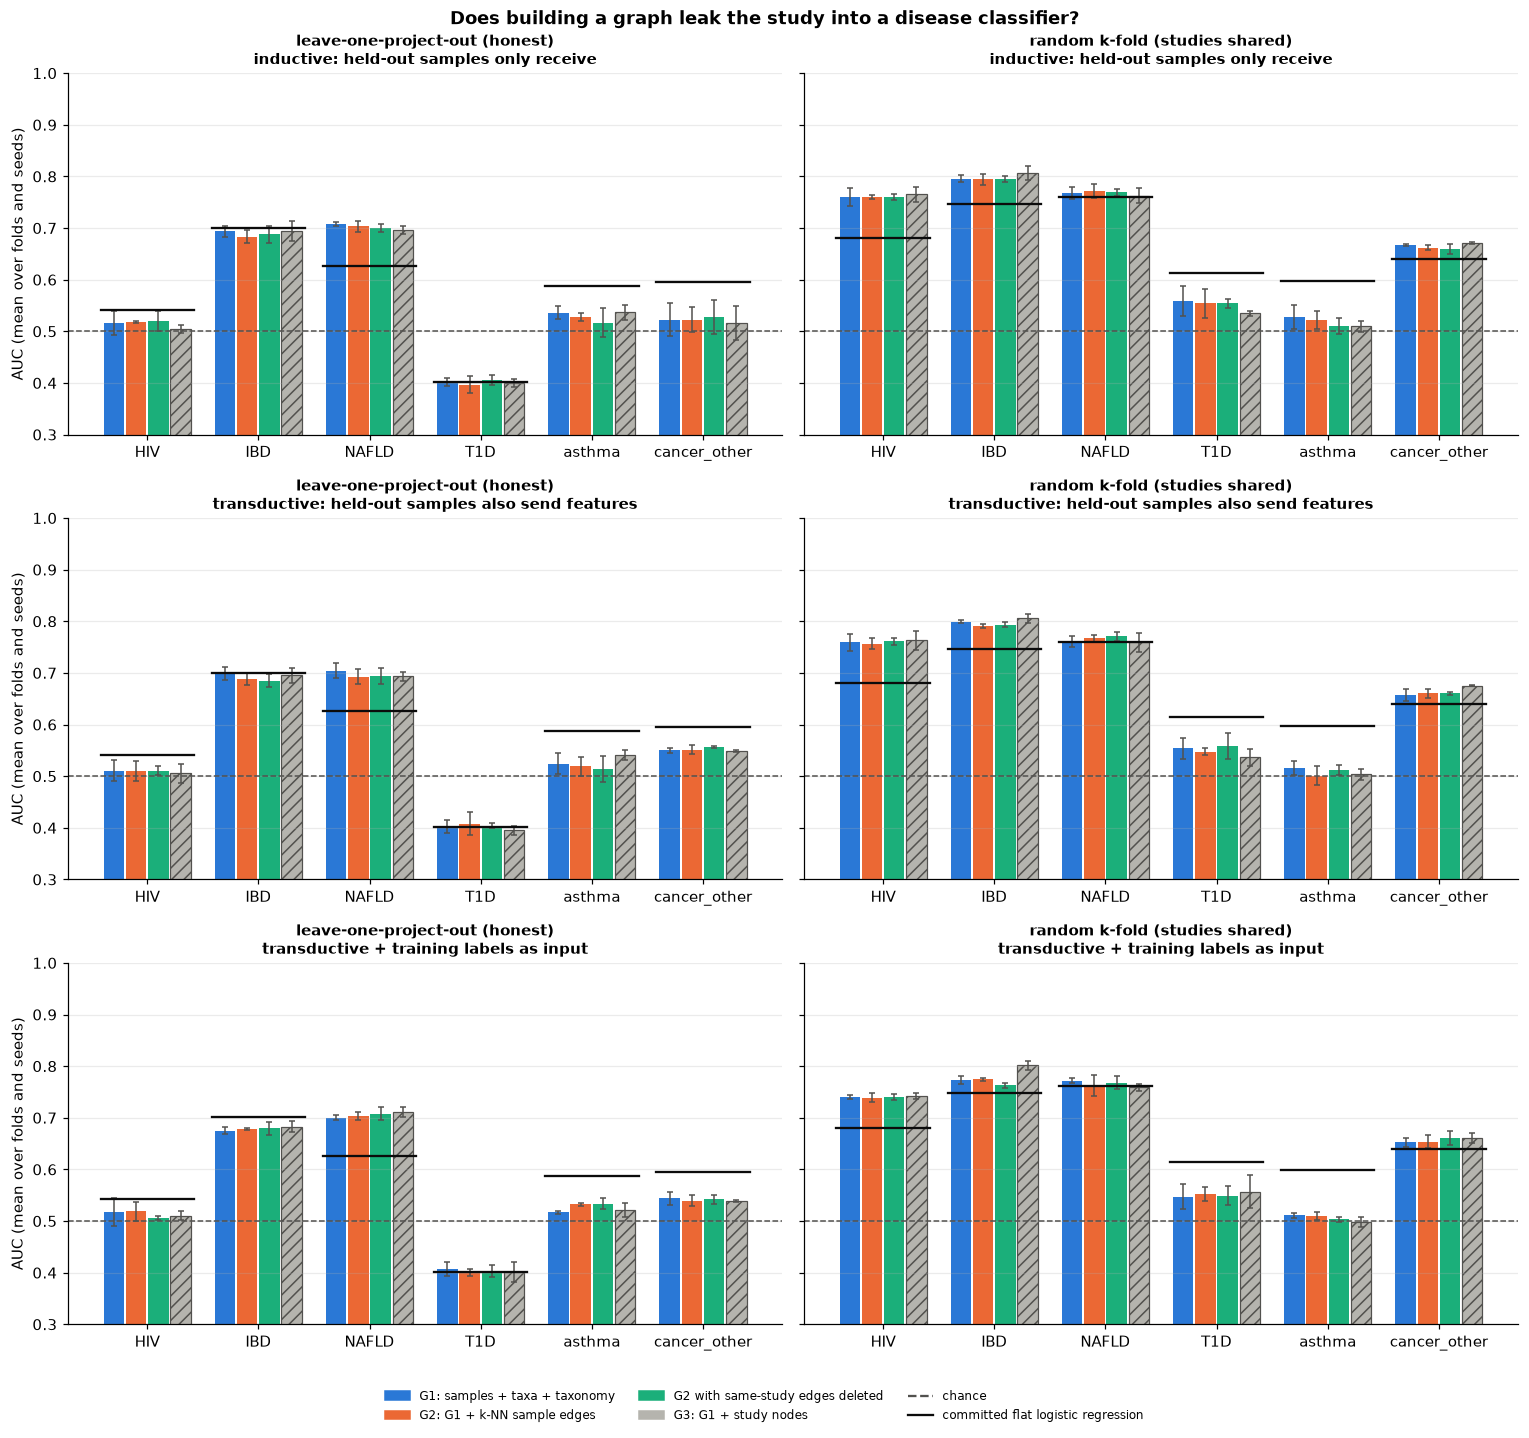

In [12]:
flat_logreg = (flat[flat["model"] == "logreg"]
               .groupby(["disease_category", "cv_scheme"])["auc"].mean().reset_index())
fig = gnn.plot_leakage_gap(auc_summary, flat=flat_logreg)
fig.savefig(FIGURES / "phase7_leakage_gap.png")